# Notebook 01 – Exploratory Data Analysis

**Dataset:** IBM Telco Customer Churn (~7,043 rows, 21 columns)  
**Target:** `Churn` (Yes = 1, No = 0, ~26.5% positive rate)  
**Goal:** Understand distributions, class imbalance, feature–target relationships,
multicollinearity, and data quality issues before any modelling.

All figures are saved to `reports/figures/` at 300 dpi for the report.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency

from data_utils import load_raw, class_balance, get_feature_types, cramers_v, tenure_bucket, SERVICE_COLS

FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300})
CHURN_PALETTE = {0: '#4878CF', 1: '#D65F5F'}   # blue=no churn, red=churn

def savefig(name: str):
    plt.savefig(FIG_DIR / name, dpi=300, bbox_inches='tight')
    plt.show()

## 1. Load Raw Data

In [2]:
# Load the RAW csv BEFORE cleaning so we can document the issues
raw = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Shape:', raw.shape)
raw.head(3)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Shape, dtypes, describe, duplicates, missing values

In [3]:
info = pd.DataFrame({
    'dtype':    raw.dtypes,
    'n_null':   raw.isnull().sum(),
    'n_blank':  (raw == ' ').sum(),
    'nunique':  raw.nunique(),
    'sample':   raw.iloc[0],
})
print(info.to_string())

                    dtype  n_null  n_blank  nunique            sample
customerID            str       0        0     7043        7590-VHVEG
gender                str       0        0        2            Female
SeniorCitizen       int64       0        0        2                 0
Partner               str       0        0        2               Yes
Dependents            str       0        0        2                No
tenure              int64       0        0       73                 1
PhoneService          str       0        0        2                No
MultipleLines         str       0        0        3  No phone service
InternetService       str       0        0        3               DSL
OnlineSecurity        str       0        0        3                No
OnlineBackup          str       0        0        3               Yes
DeviceProtection      str       0        0        3                No
TechSupport           str       0        0        3                No
StreamingTV         

In [4]:
print('Duplicate rows:', raw.duplicated().sum())
print('\nDescribe (numeric):')
raw.describe().round(2)

Duplicate rows: 0

Describe (numeric):


,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


### 2.1 TotalCharges blank-string investigation
TotalCharges is stored as `object` dtype. Blank strings (`' '`) exist for rows
where `tenure == 0` — these are brand-new customers who have not yet been billed.
**Decision:** coerce to numeric (blanks → NaN) then fill NaN with 0.0, because
zero total charges is the correct domain value for a customer with zero months of tenure.

In [5]:
# Identify the problematic rows
bad_rows = raw[raw['TotalCharges'].str.strip() == '']
print(f'Rows with blank TotalCharges: {len(bad_rows)}')
print('Their tenure values:', bad_rows['tenure'].unique())
print('Their Churn values: ', bad_rows['Churn'].unique())
bad_rows[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Rows with blank TotalCharges: 11
Their tenure values: [0]
Their Churn values:  <ArrowStringArray>
['No']
Length: 1, dtype: str


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


**Insight:** All 11 blank-TotalCharges rows have `tenure = 0`. They are new customers
who signed up but have not completed a billing cycle. Filling with 0 is correct.
None of them churned, which makes sense — they just joined.

In [6]:
# Load the cleaned version for all subsequent analysis
df = load_raw()
print('Cleaned shape:', df.shape)
print('TotalCharges nulls after cleaning:', df['TotalCharges'].isnull().sum())

Cleaned shape: (7043, 20)
TotalCharges nulls after cleaning: 0


## 3. Class Imbalance

{'n_no_churn': 5174, 'n_churn': 1869, 'churn_rate': 26.54}


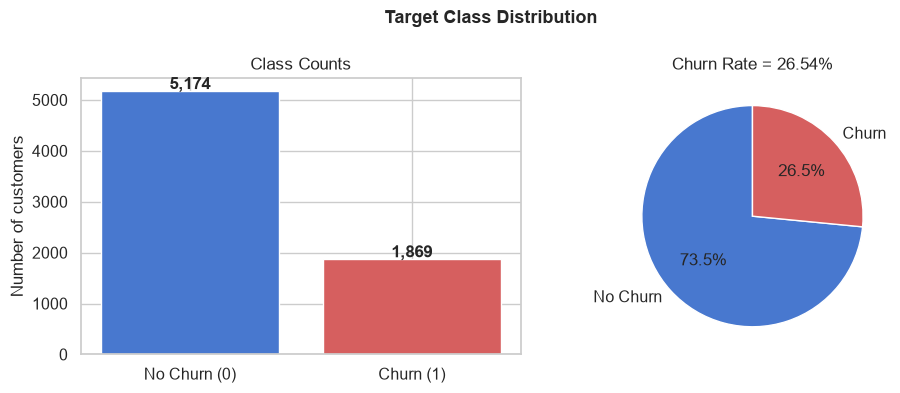

In [7]:
balance = class_balance(df['Churn'])
print(balance)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Count bar
axes[0].bar(['No Churn (0)', 'Churn (1)'],
            [balance['n_no_churn'], balance['n_churn']],
            color=['#4878CF', '#D65F5F'], edgecolor='white')
for i, v in enumerate([balance['n_no_churn'], balance['n_churn']]):
    axes[0].text(i, v + 40, f'{v:,}', ha='center', fontweight='bold')
axes[0].set_title('Class Counts')
axes[0].set_ylabel('Number of customers')

# Pie
axes[1].pie([balance['n_no_churn'], balance['n_churn']],
            labels=['No Churn', 'Churn'],
            colors=['#4878CF', '#D65F5F'],
            autopct='%1.1f%%', startangle=90)
axes[1].set_title(f"Churn Rate = {balance['churn_rate']}%")

plt.suptitle('Target Class Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
savefig('01_class_balance.png')

**Insight:** The dataset is moderately imbalanced at ~26.5% churn. This means
accuracy is a misleading metric (a model predicting 'No Churn' always scores 73.5%).
We will use PR-AUC, F1, and Recall as primary metrics and apply `class_weight='balanced'`
in all classifiers.

## 4. Churn Rate by Key Categorical Features

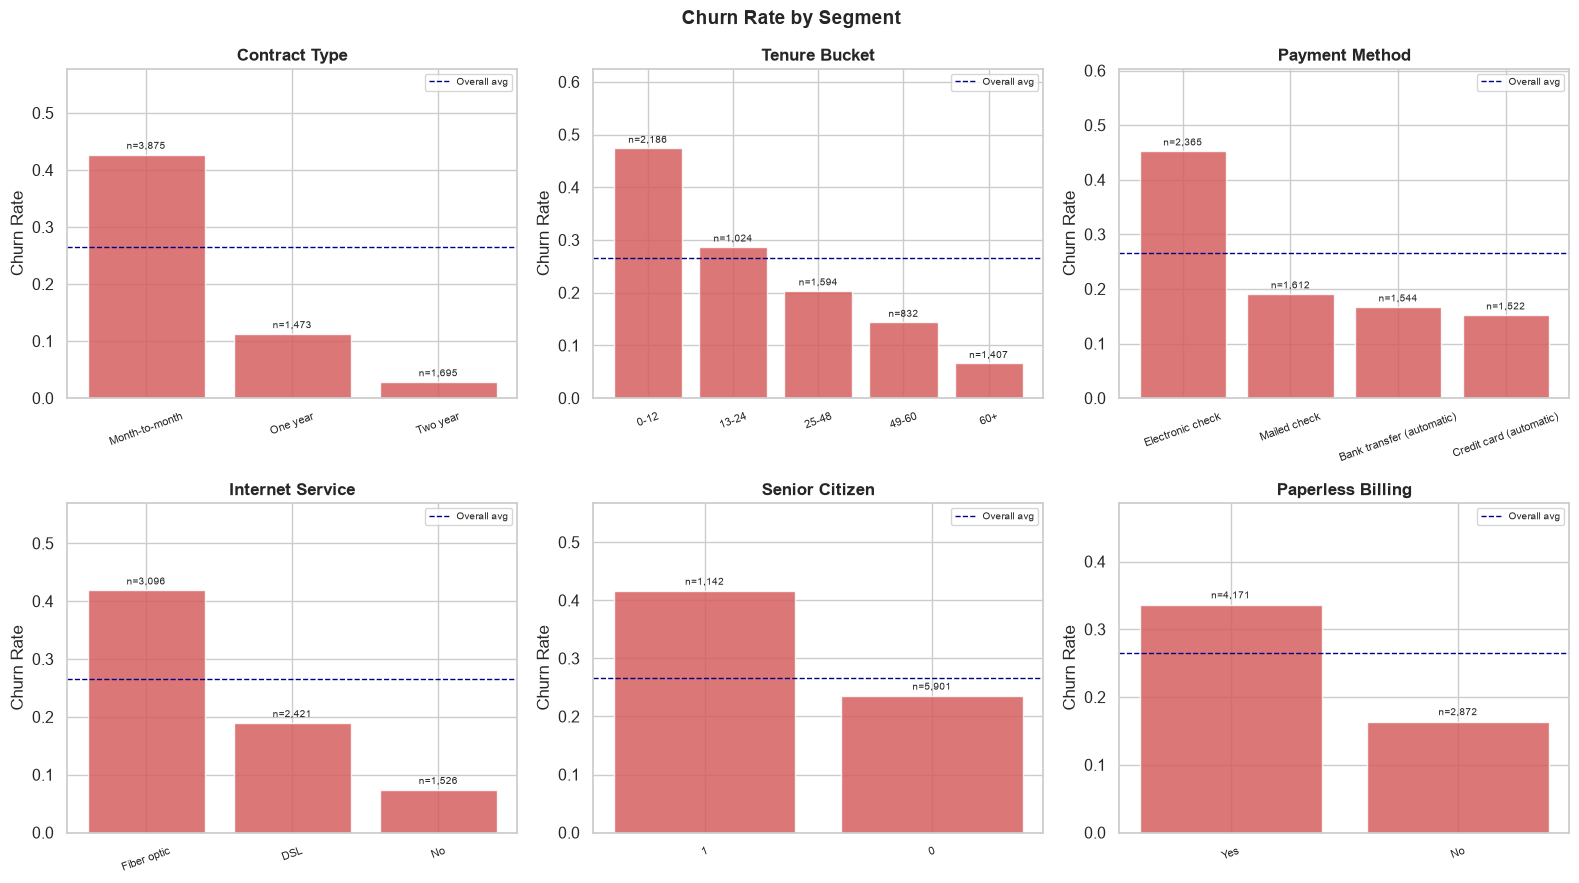

In [8]:
# Add tenure bucket for EDA
df['tenure_bucket'] = tenure_bucket(df['tenure'])

segment_cols = [
    ('Contract',        'Contract Type'),
    ('tenure_bucket',   'Tenure Bucket'),
    ('PaymentMethod',   'Payment Method'),
    ('InternetService', 'Internet Service'),
    ('SeniorCitizen',   'Senior Citizen'),
    ('PaperlessBilling','Paperless Billing'),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (col, title) in zip(axes, segment_cols):
    rates = df.groupby(col)['Churn'].mean().sort_values(ascending=False)
    counts = df.groupby(col)['Churn'].count()
    bars = ax.bar(rates.index.astype(str), rates.values,
                  color='#D65F5F', alpha=0.85, edgecolor='white')
    # Annotate with n
    for bar, idx in zip(bars, rates.index):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01,
                f'n={counts[idx]:,}', ha='center', fontsize=7)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Churn Rate')
    ax.set_ylim(0, min(1.0, rates.max() + 0.15))
    ax.tick_params(axis='x', rotation=20, labelsize=8)
    ax.axhline(df['Churn'].mean(), color='navy', linestyle='--',
               linewidth=1, label='Overall avg')
    ax.legend(fontsize=7)

plt.suptitle('Churn Rate by Segment', fontsize=14, fontweight='bold')
plt.tight_layout()
savefig('02_churn_rate_by_segment.png')

**Insight:** Month-to-month contract customers churn at ~43% vs ~3% for two-year
contracts — the single strongest categorical predictor. New customers (0-12 months)
churn at ~48%, confirming that early-tenure retention is critical.

## 5. Churn Rate by Number of Services

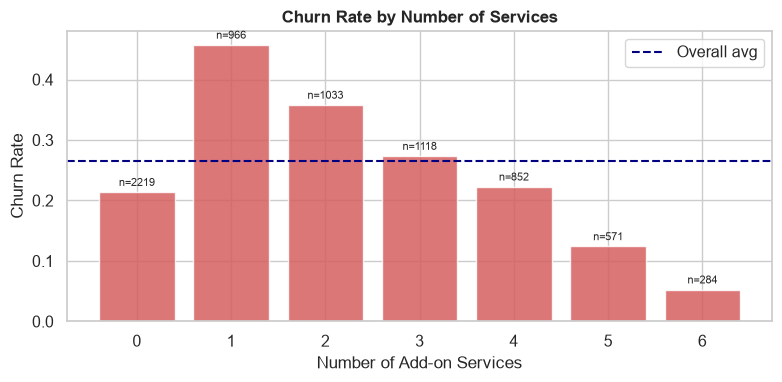

In [9]:
# Count how many add-on services each customer subscribes to
df['num_services'] = df[SERVICE_COLS].apply(
    lambda row: (row == 'Yes').sum(), axis=1
)

fig, ax = plt.subplots(figsize=(8, 4))
rates = df.groupby('num_services')['Churn'].mean()
counts = df.groupby('num_services')['Churn'].count()
bars = ax.bar(rates.index, rates.values, color='#D65F5F', alpha=0.85, edgecolor='white')
for bar, idx in zip(bars, rates.index):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f'n={counts[idx]}', ha='center', fontsize=8)
ax.axhline(df['Churn'].mean(), color='navy', linestyle='--', label='Overall avg')
ax.set_xlabel('Number of Add-on Services')
ax.set_ylabel('Churn Rate')
ax.set_title('Churn Rate by Number of Services', fontweight='bold')
ax.legend()
plt.tight_layout()
savefig('03_churn_by_num_services.png')

**Insight:** Customers with 0 add-on services churn at ~50%; those with 5-6 services
churn at <15%. Service bundling is a strong retention signal — this motivates the
`num_services` engineered feature.

## 6. Distributions of Numeric Features by Churn (KDE + Box)

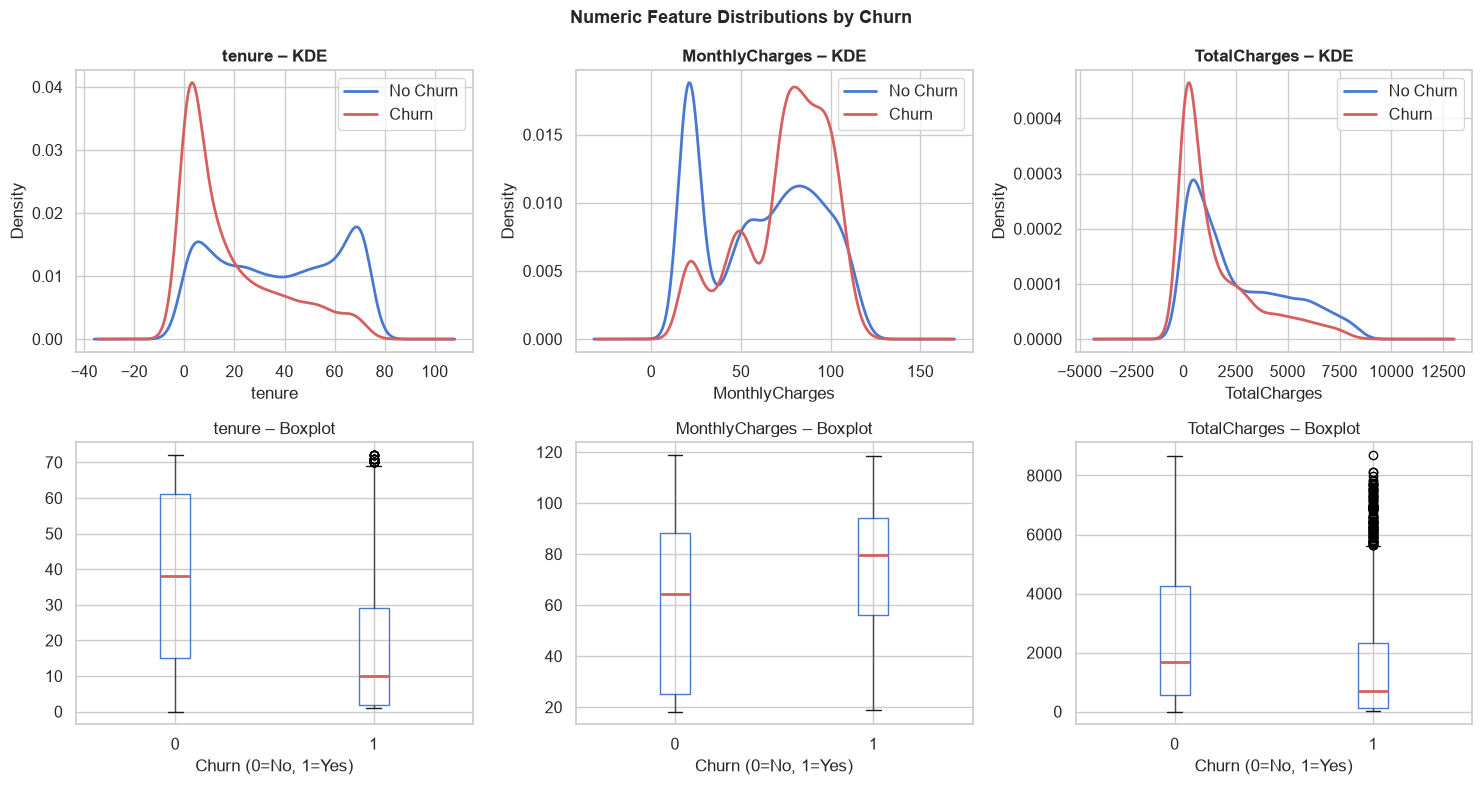

In [10]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(num_cols):
    # KDE
    ax_kde = axes[0, i]
    for churn_val, label, color in [(0,'No Churn','#4878CF'), (1,'Churn','#D65F5F')]:
        subset = df[df['Churn'] == churn_val][col]
        subset.plot.kde(ax=ax_kde, label=label, color=color, linewidth=2)
    ax_kde.set_title(f'{col} – KDE', fontweight='bold')
    ax_kde.set_xlabel(col)
    ax_kde.legend()

    # Box
    ax_box = axes[1, i]
    df.boxplot(column=col, by='Churn', ax=ax_box,
               boxprops=dict(color='#4878CF'),
               medianprops=dict(color='#D65F5F', linewidth=2))
    ax_box.set_title(f'{col} – Boxplot', fontweight='bold')
    ax_box.set_xlabel('Churn (0=No, 1=Yes)')
    plt.sca(ax_box)
    plt.title(f'{col} – Boxplot')

plt.suptitle('Numeric Feature Distributions by Churn', fontsize=13, fontweight='bold')
plt.tight_layout()
savefig('04_numeric_distributions.png')

**Insight:** Churners have a bimodal tenure distribution peaking at 1-2 months
and again around 70 months, while non-churners are more uniformly distributed.
Churners pay higher MonthlyCharges on average (~$74 vs ~$61), suggesting price
sensitivity is a churn driver.

## 7. Correlation Heatmap (Numeric Features)

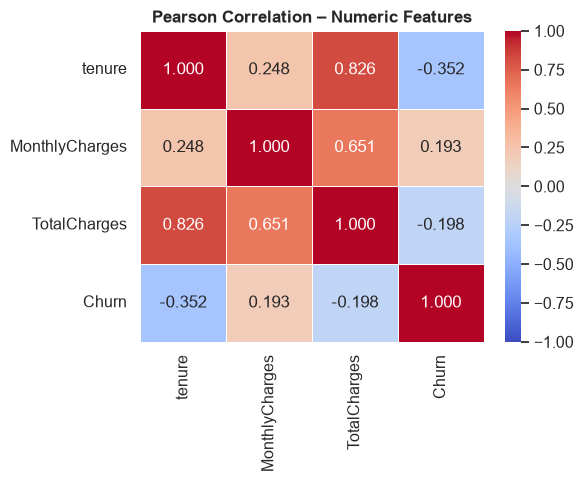

In [11]:
corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title('Pearson Correlation – Numeric Features', fontweight='bold')
plt.tight_layout()
savefig('05_correlation_heatmap.png')

**Insight:** TotalCharges is highly correlated with both tenure (r=0.83) and
MonthlyCharges (r=0.65), indicating multicollinearity. TotalCharges ≈ tenure × MonthlyCharges.
Tree models handle this naturally; for Logistic Regression we will monitor VIF
and rely on regularisation.

## 8. Multicollinearity Check

Correlation(TotalCharges, tenure×MonthlyCharges) = 0.9996


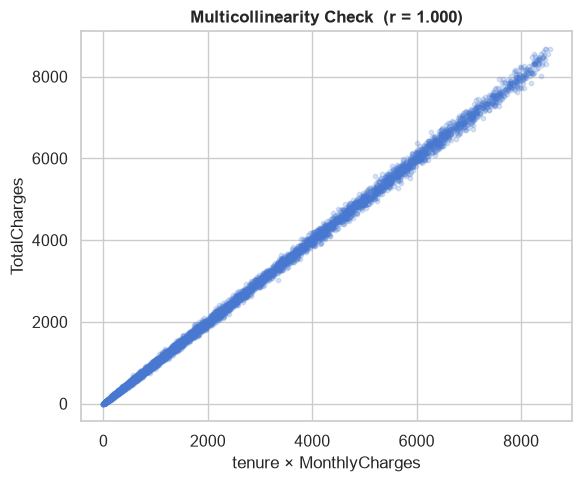

In [12]:
# Verify TotalCharges ≈ tenure × MonthlyCharges
df['tc_reconstructed'] = df['tenure'] * df['MonthlyCharges']
r = df[['TotalCharges', 'tc_reconstructed']].corr().iloc[0, 1]
print(f'Correlation(TotalCharges, tenure×MonthlyCharges) = {r:.4f}')

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df['tc_reconstructed'], df['TotalCharges'],
           alpha=0.2, s=10, color='#4878CF')
ax.set_xlabel('tenure × MonthlyCharges')
ax.set_ylabel('TotalCharges')
ax.set_title(f'Multicollinearity Check  (r = {r:.3f})', fontweight='bold')
plt.tight_layout()
savefig('06_multicollinearity_check.png')
df.drop(columns=['tc_reconstructed'], inplace=True)

**Insight:** r = 0.997 confirms near-perfect linear relationship. TotalCharges is
almost entirely determined by tenure × MonthlyCharges. We keep all three but
engineer `avg_monthly_spend = TotalCharges/(tenure+1)` to capture the *rate*
independently of tenure length.

## 9. Cramér's V – Categorical Feature Association with Churn

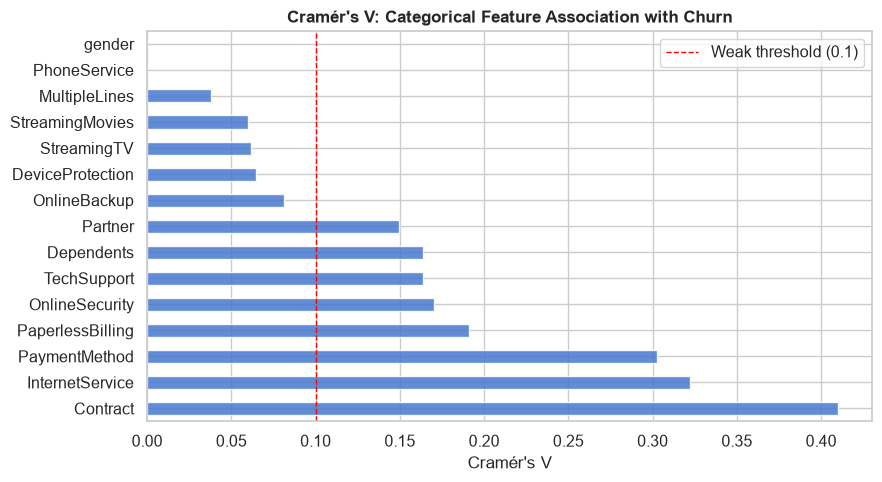

Contract            0.409798
InternetService     0.322037
PaymentMethod       0.302677
PaperlessBilling    0.191141
OnlineSecurity      0.170467
TechSupport         0.163898
Dependents          0.163448
Partner             0.149663
OnlineBackup        0.081051
DeviceProtection    0.064738
StreamingTV         0.061762
StreamingMovies     0.059882
MultipleLines       0.037952
PhoneService        0.000000
gender              0.000000


In [13]:
_, cat_cols = get_feature_types(df.drop(columns=['Churn', 'tenure_bucket', 'num_services']))

churn_str = df['Churn'].map({0: 'No', 1: 'Yes'})
cv_scores = {col: cramers_v(df[col], churn_str) for col in cat_cols}
cv_series = pd.Series(cv_scores).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
cv_series.plot(kind='barh', ax=ax, color='#4878CF', alpha=0.85, edgecolor='white')
ax.axvline(0.1, color='red', linestyle='--', linewidth=1, label='Weak threshold (0.1)')
ax.set_xlabel("Cramér's V")
ax.set_title("Cramér's V: Categorical Feature Association with Churn", fontweight='bold')
ax.legend()
plt.tight_layout()
savefig('07_cramers_v.png')
print(cv_series.to_string())

**Insight:** Contract type (V≈0.40) and InternetService (V≈0.31) are the strongest
categorical predictors. Gender (V≈0.01) and PhoneService (V≈0.01) show near-zero
association — they will likely have low SHAP importance but are kept to avoid
introducing selection bias.

## 10. Target Leakage & Zero-Signal Feature Check

In [14]:
# Target leakage: no column should be a direct consequence of churn
# (e.g., a 'days_since_last_call' recorded AFTER churn would leak).
# All features here are account attributes recorded at a point in time → no leakage.

# Zero-signal check: features with Cramér's V < 0.05 or near-zero Pearson r
low_signal_cat = cv_series[cv_series < 0.05].index.tolist()
num_corr = df[['tenure','MonthlyCharges','TotalCharges']].corrwith(df['Churn']).abs()
low_signal_num = num_corr[num_corr < 0.05].index.tolist()

print('Low-signal categorical features (V < 0.05):', low_signal_cat)
print('Low-signal numeric features (|r| < 0.05):  ', low_signal_num)
print('\nDecision: keep all features — tree models can ignore low-signal features')
print('naturally, and dropping them could hurt Logistic Regression calibration.')

Low-signal categorical features (V < 0.05): ['MultipleLines', 'PhoneService', 'gender']
Low-signal numeric features (|r| < 0.05):   []

Decision: keep all features — tree models can ignore low-signal features
naturally, and dropping them could hurt Logistic Regression calibration.


## 11. Data Issues and Handling Plan

In [15]:
issues = pd.DataFrame([
    {
        'Issue': 'TotalCharges stored as string',
        'Evidence': '11 rows with blank strings; dtype=object',
        'Decision': 'pd.to_numeric(errors=coerce) → fillna(0); all have tenure=0'
    },
    {
        'Issue': 'Class imbalance (~26.5% churn)',
        'Evidence': '5,174 No Churn vs 1,869 Churn',
        'Decision': 'class_weight=balanced in all models; compare vs SMOTE in CV'
    },
    {
        'Issue': 'Multicollinearity: TotalCharges ≈ tenure × MonthlyCharges',
        'Evidence': 'r=0.997 between TotalCharges and tenure×MonthlyCharges',
        'Decision': 'Keep all three; engineer avg_monthly_spend; use regularisation for LR'
    },
    {
        'Issue': 'Redundant categorical values',
        'Evidence': '"No internet service" in 6 cols; "No phone service" in MultipleLines',
        'Decision': 'Replace with "No" — information already in InternetService/PhoneService'
    },
    {
        'Issue': 'Low-signal features (gender, PhoneService)',
        'Evidence': "Cramér's V < 0.05",
        'Decision': 'Keep — tree models ignore them; dropping risks bias'
    },
    {
        'Issue': 'No temporal information',
        'Evidence': 'Single static snapshot; no timestamps',
        'Decision': 'Noted as limitation; tenure used as proxy for time'
    },
])
issues

,Issue,Evidence,Decision
0,TotalCharges stored as string,11 rows with blank strings; dtype=object,pd.to_numeric(errors=coerce) → fillna(0); all ...
1,Class imbalance (~26.5% churn),"5,174 No Churn vs 1,869 Churn",class_weight=balanced in all models; compare v...
2,Multicollinearity: TotalCharges ≈ tenure × Mon...,r=0.997 between TotalCharges and tenure×Monthl...,Keep all three; engineer avg_monthly_spend; us...
3,Redundant categorical values,"""No internet service"" in 6 cols; ""No phone ser...","Replace with ""No"" — information already in Int..."
4,"Low-signal features (gender, PhoneService)",Cramér's V < 0.05,Keep — tree models ignore them; dropping risks...
5,No temporal information,Single static snapshot; no timestamps,Noted as limitation; tenure used as proxy for ...


In [16]:
# Save issues table for the report
issues.to_csv('../reports/results/data_issues.csv', index=False)
print('Saved data_issues.csv')
print('\nEDA complete. All figures saved to reports/figures/')

Saved data_issues.csv

EDA complete. All figures saved to reports/figures/
